Name: Kriti Bhattacharya
Github: Kritiin5
USC ID: 3277100685

In [7]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

acute_data = fetch_ucirepo(id=184)

X = acute_data.data.features
y = acute_data.data.targets

data = pd.concat([X, y], axis=1)

data.head()

,temperature,nausea,lumbar-pain,urine-pushing,micturition-pains,burning-urethra,bladder-inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


1b.

In [9]:
feature_names = ['temperature', 'nausea', 'lumbar-pain', 'urine-pushing', 'micturition-pains', 'burning-urethra']

X = data[feature_names].copy()

for column in feature_names[1:]:
    X[column] = X[column].map({'no': 0, 'yes': 1})

y = data['bladder-inflammation'] + '_' + data['nephritis']

In [10]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=552)
tree_model.fit(X, y)

print("Tree depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())

Tree depth: 4
Number of leaves: 6


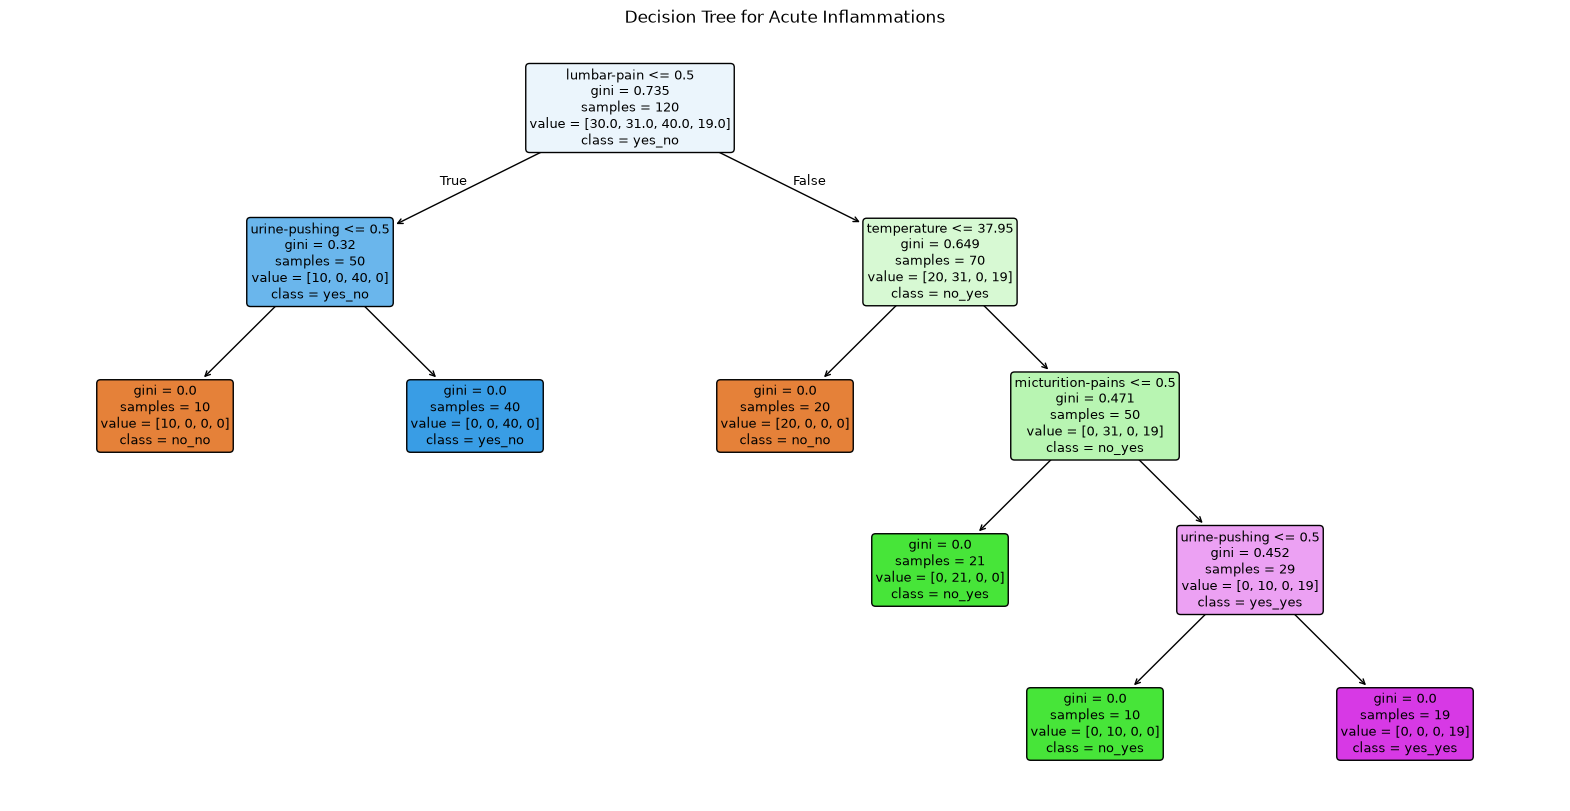

In [11]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(tree_model, feature_names=feature_names, class_names=tree_model.classes_, filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree for Acute Inflammations')
plt.show()

1c.

In [12]:
from sklearn.tree import export_text

rules = export_text(tree_model, feature_names=feature_names)
print(rules)

|--- lumbar-pain <= 0.50
|   |--- urine-pushing <= 0.50
|   |   |--- class: no_no
|   |--- urine-pushing >  0.50
|   |   |--- class: yes_no
|--- lumbar-pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: no_no
|   |--- temperature >  37.95
|   |   |--- micturition-pains <= 0.50
|   |   |   |--- class: no_yes
|   |   |--- micturition-pains >  0.50
|   |   |   |--- urine-pushing <= 0.50
|   |   |   |   |--- class: no_yes
|   |   |   |--- urine-pushing >  0.50
|   |   |   |   |--- class: yes_yes



1d.

In [13]:
from sklearn.model_selection import cross_val_score

path = tree_model.cost_complexity_pruning_path(X, y)
alpha_values = path.ccp_alphas[:-1]

print(alpha_values)

cv_results = []

for alpha in alpha_values:
    model = DecisionTreeClassifier(random_state=552, ccp_alpha=alpha)
    accuracy = cross_val_score(model, X, y, cv=5, scoring='accuracy').mean()
    cv_results.append({'Alpha': alpha, 'CV Accuracy': accuracy})

cv_table = pd.DataFrame(cv_results)
cv_table

[0.         0.09816667 0.13333333 0.182     ]


,Alpha,CV Accuracy
0,0.000000,0.958333
1,0.098167,0.775000
2,0.133333,0.716667
3,0.182000,0.600000


In [14]:
best_accuracy = cv_table['CV Accuracy'].max()
best_alpha = cv_table.loc[cv_table['CV Accuracy'] == best_accuracy, 'Alpha'].max()

print("Best alpha:", best_alpha)
print("Best CV accuracy:", best_accuracy)

Best alpha: 0.0
Best CV accuracy: 0.9583333333333334


Original tree depth: 4
Pruned tree depth: 4
Original number of leaves: 6
Pruned number of leaves: 6


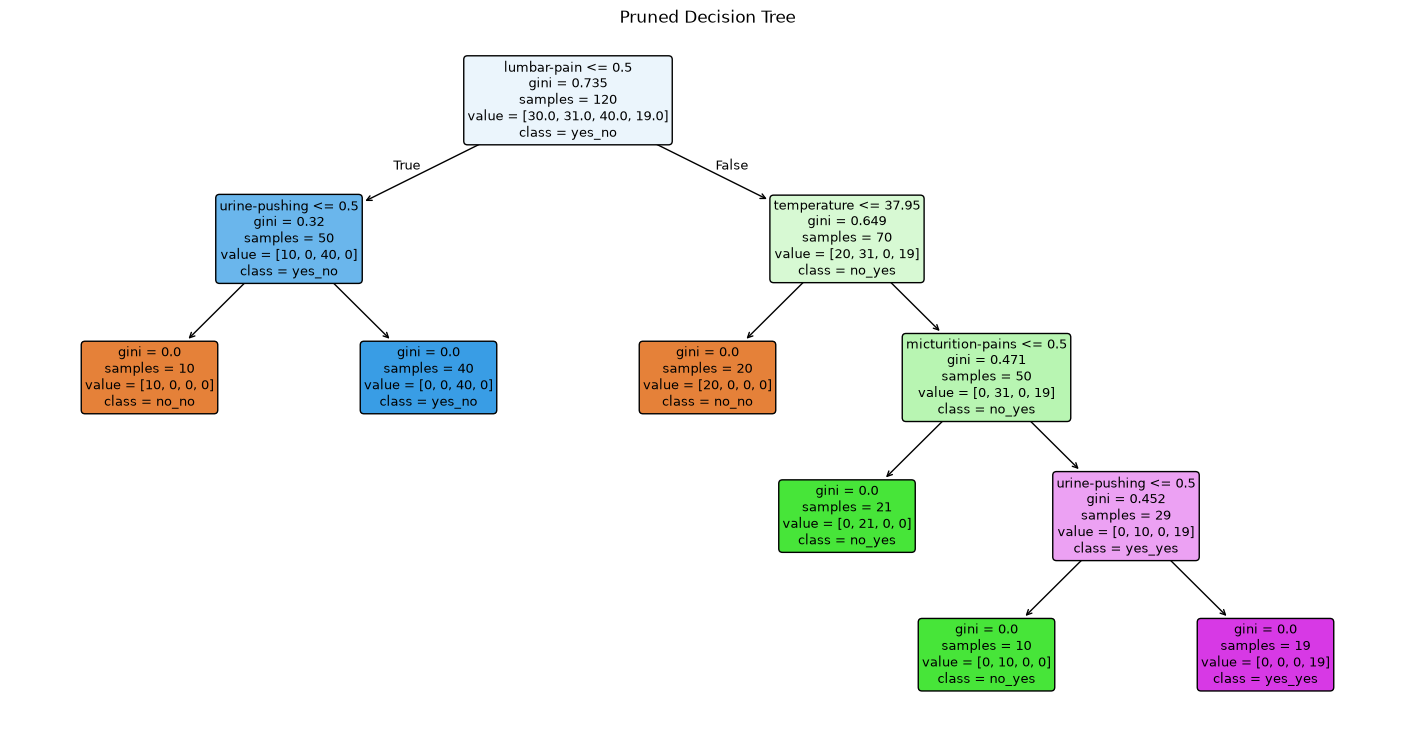

In [15]:
pruned_tree = DecisionTreeClassifier(random_state=552, ccp_alpha=best_alpha)
pruned_tree.fit(X, y)

print("Original tree depth:", tree_model.get_depth())
print("Pruned tree depth:", pruned_tree.get_depth())
print("Original number of leaves:", tree_model.get_n_leaves())
print("Pruned number of leaves:", pruned_tree.get_n_leaves())


plt.figure(figsize=(18, 9))
plot_tree(pruned_tree, feature_names=feature_names, class_names=pruned_tree.classes_, filled=True, rounded=True, fontsize=9)
plt.title('Pruned Decision Tree')
plt.show()

In [16]:
pruned_rules = export_text(pruned_tree, feature_names=feature_names)
print(pruned_rules)

|--- lumbar-pain <= 0.50
|   |--- urine-pushing <= 0.50
|   |   |--- class: no_no
|   |--- urine-pushing >  0.50
|   |   |--- class: yes_no
|--- lumbar-pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: no_no
|   |--- temperature >  37.95
|   |   |--- micturition-pains <= 0.50
|   |   |   |--- class: no_yes
|   |   |--- micturition-pains >  0.50
|   |   |   |--- urine-pushing <= 0.50
|   |   |   |   |--- class: no_yes
|   |   |   |--- urine-pushing >  0.50
|   |   |   |   |--- class: yes_yes



2a.

In [17]:
column_names = []

with open('../data/communities.names', 'r', encoding='latin-1') as file:
    for line in file:
        if line.startswith('@attribute'):
            column_names.append(line.split()[1])

print("Number of columns:", len(column_names))

crime_data = pd.read_csv('../data/communities.data', header=None, names=column_names, na_values='?')

print("Dataset shape:", crime_data.shape)
#crime_data.head()

train_data = crime_data.iloc[:1495].copy()
test_data = crime_data.iloc[1495:].copy()

print("Training set shape:", train_data.shape)
print("Testing set shape:", test_data.shape)

Number of columns: 128
Dataset shape: (1994, 128)
Training set shape: (1495, 128)
Testing set shape: (499, 128)


2b.

In [18]:
nonpredictive = ['state', 'county', 'community', 'communityname', 'fold']
target = 'ViolentCrimesPerPop'

X_train = train_data.drop(columns=nonpredictive + [target])
y_train = train_data[target]

X_test = test_data.drop(columns=nonpredictive + [target])
y_test = test_data[target]

print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())

Training missing values: 27633
Testing missing values: 9218


In [19]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Training missing values after imputation:", X_train.isnull().sum().sum())
print("Testing missing values after imputation:", X_test.isnull().sum().sum())

Training missing values after imputation: 0
Testing missing values after imputation: 0


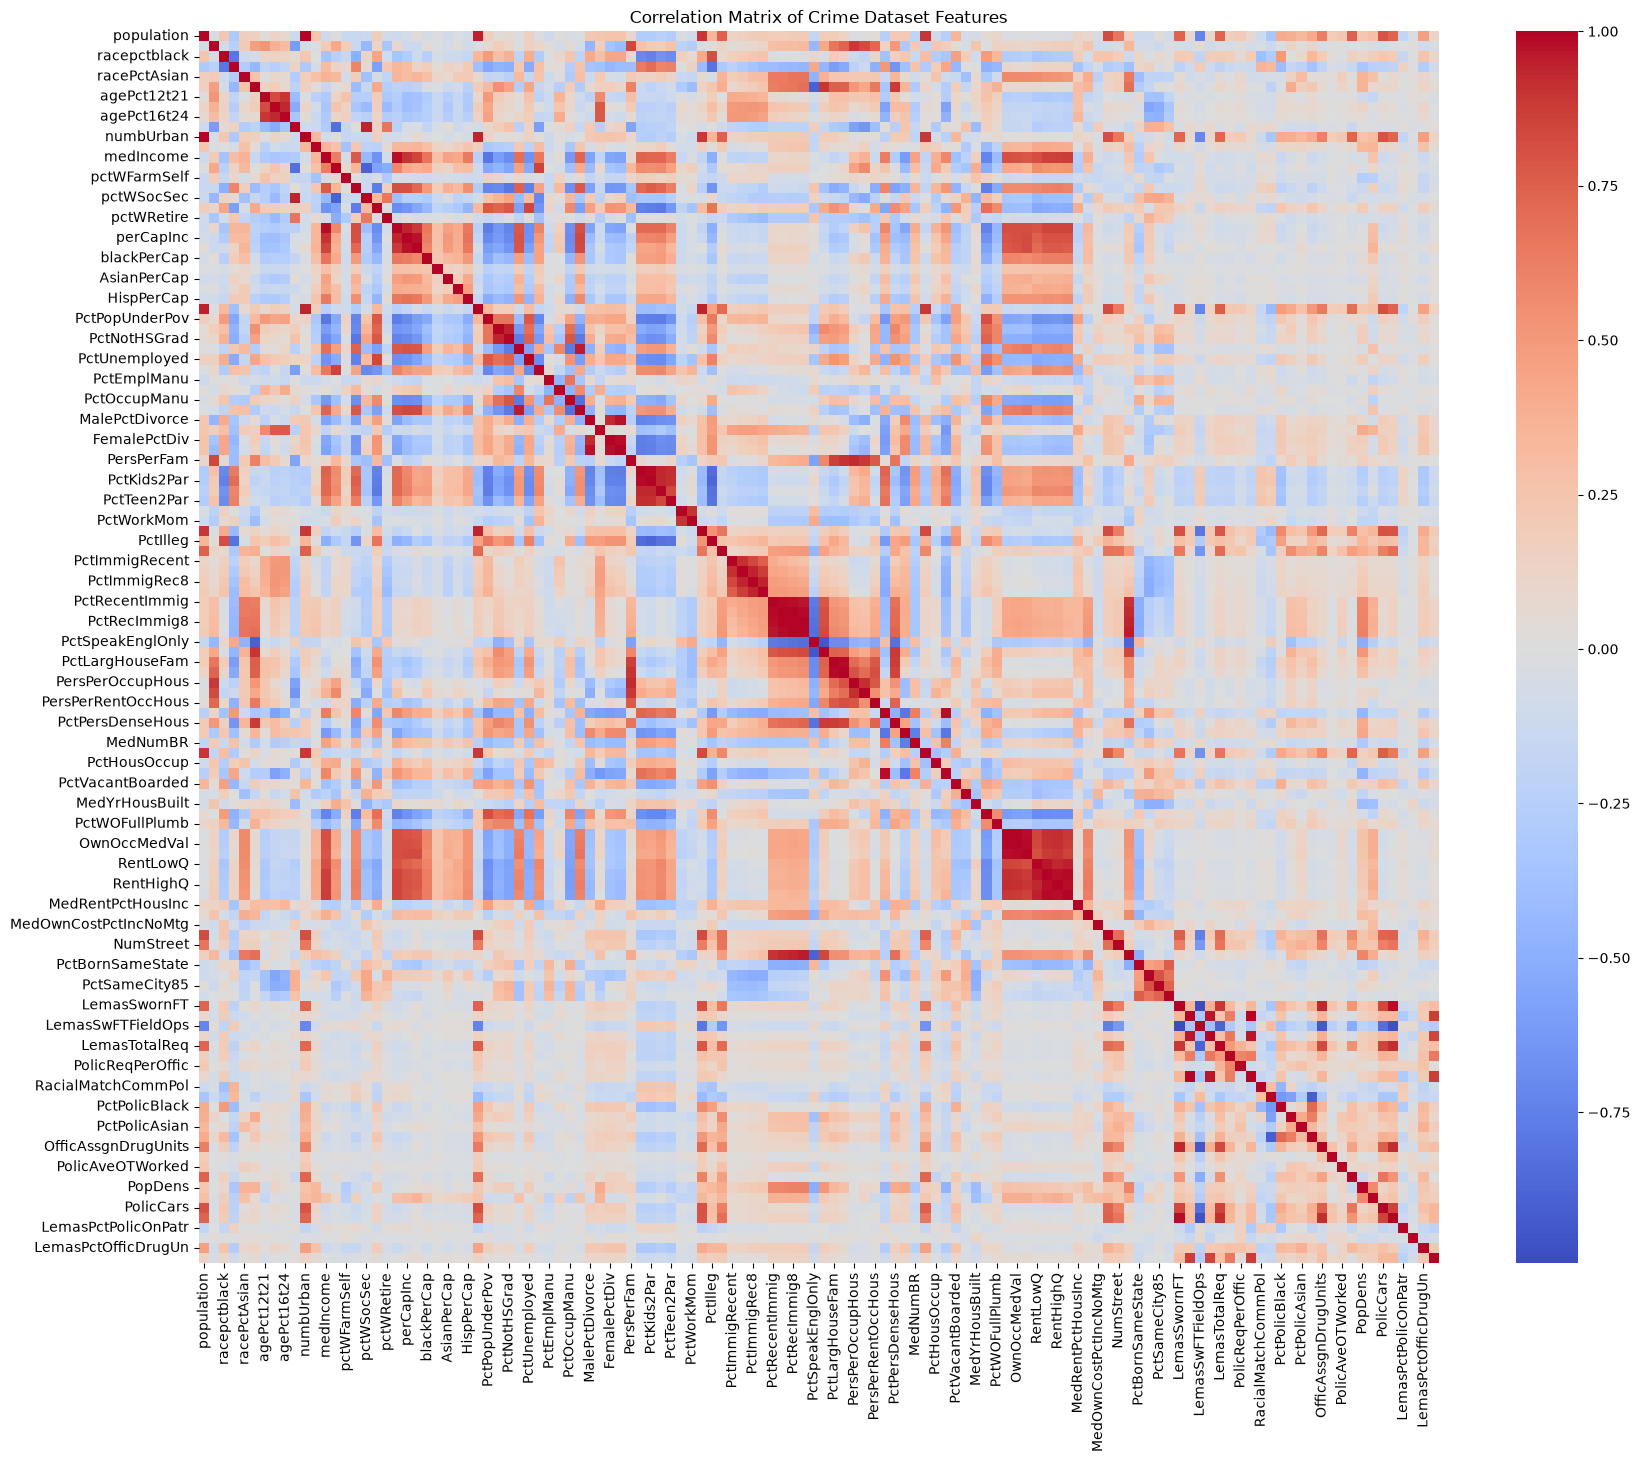

In [20]:
import seaborn as sns
correlation_matrix = X_train.corr()

plt.figure(figsize=(20, 16))
sns.heatmap(correlation_matrix, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Crime Dataset Features')
plt.show()

2d.

In [21]:
feature_cv = X_train.std() / X_train.mean()

cv_table = pd.DataFrame({'Feature': feature_cv.index, 'CV': feature_cv.values})
cv_table = cv_table.sort_values(by='CV', ascending=False).reset_index(drop=True)

cv_table

,Feature,CV
0,PctPolicAsian,5.527059
1,NumStreet,4.292923
2,NumInShelters,3.470952
3,NumIlleg,3.058964
4,NumImmig,2.926635
...,...,...
117,NumKindsDrugsSeiz,0.141021
118,RacialMatchCommPol,0.129652
119,PctPolicWhite,0.118727
120,LemasPctPolicOnPatr,0.112032


2e.

In [22]:
number_of_features = int(np.floor(np.sqrt(128)))
top_features = cv_table.head(number_of_features)['Feature'].tolist()

print("Selected features:")
print(top_features)

Selected features:
['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']


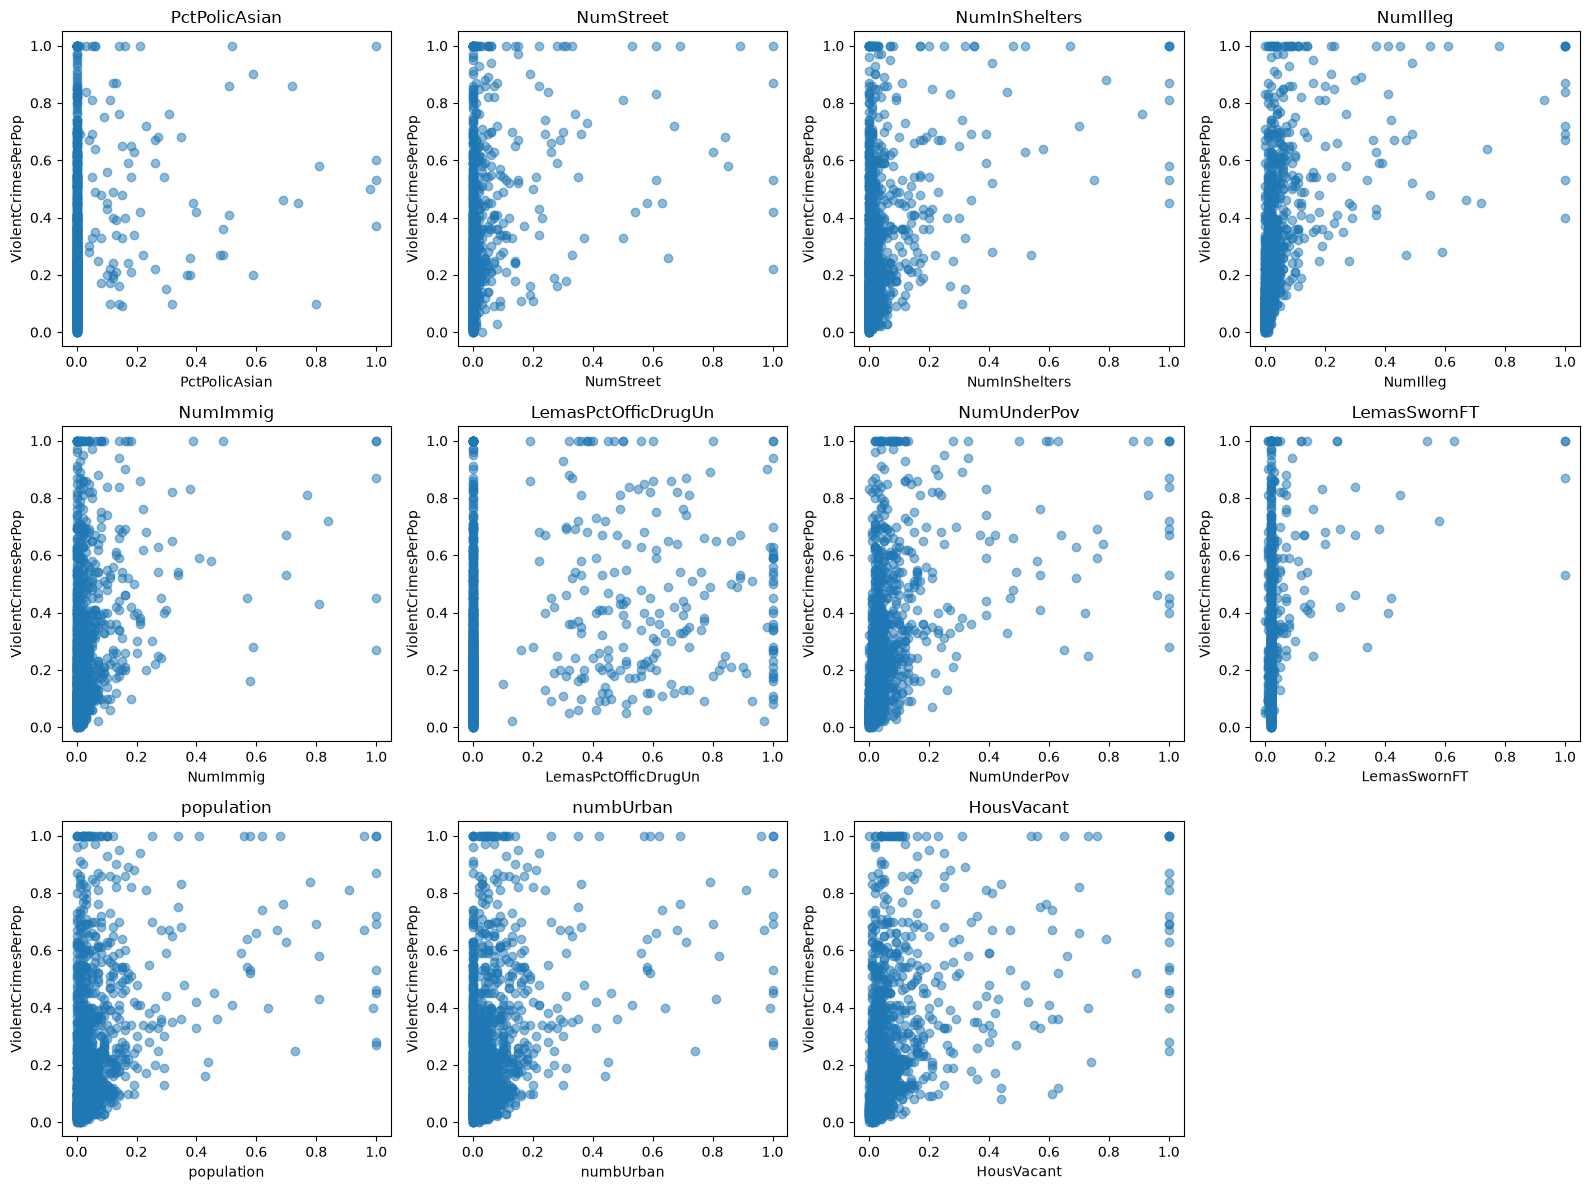

In [23]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(X_train[feature], y_train, alpha=0.5)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('ViolentCrimesPerPop')
    axes[i].set_title(feature)

axes[-1].axis('off')
plt.tight_layout()
plt.show()

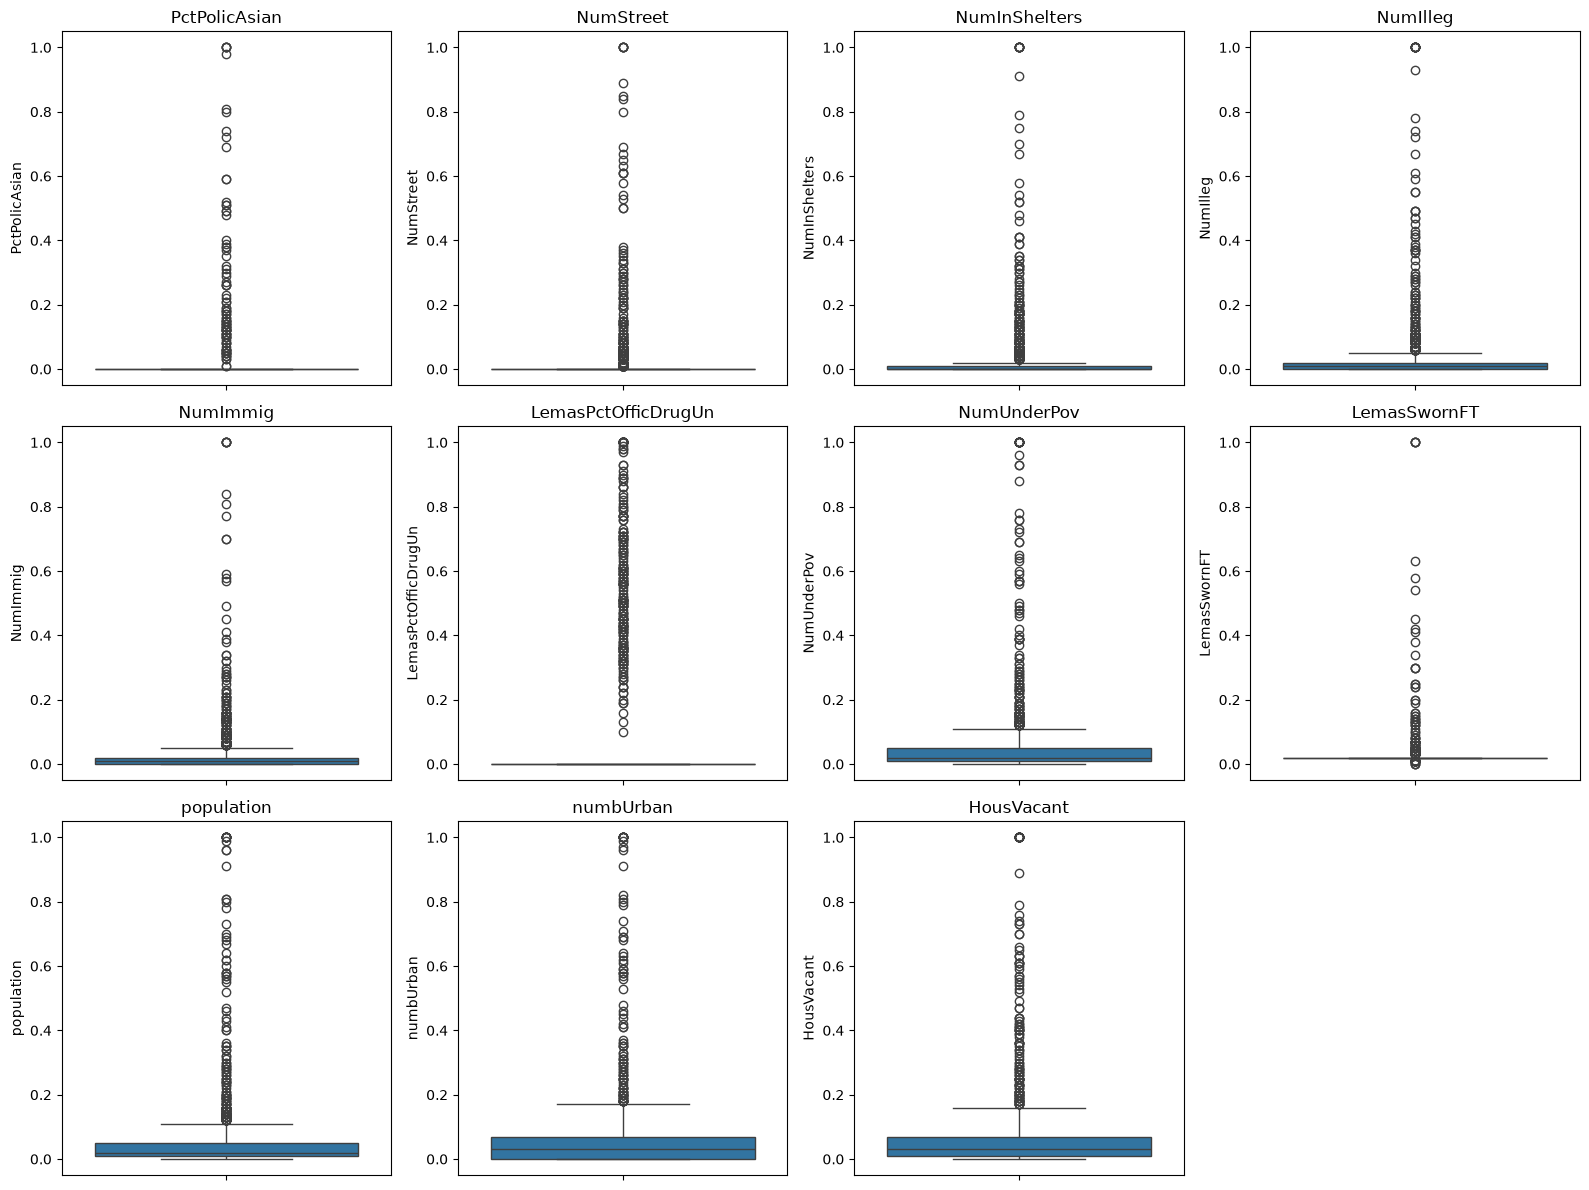

In [24]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(y=X_train[feature], ax=axes[i])
    axes[i].set_title(feature)

axes[-1].axis('off')
plt.tight_layout()
plt.show()

The scatterplots show that some features may have relationships with violent crime, while others show weak or unclear patterns. But statistical significance cannot be determined from scatterplots alone. A regression model or statistical test is needed to determine whether the features are significant.

2f.

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)
linear_test_error = mean_squared_error(y_test, linear_predictions)

print("Linear regression test error:", linear_test_error)

Linear regression test error: 0.01796621542606732


2g.

In [26]:
from sklearn.linear_model import RidgeCV

alpha_values = np.logspace(-4, 4, 100)

ridge_model = RidgeCV(alphas=alpha_values, cv=5, scoring='neg_mean_squared_error')
ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)
ridge_test_error = mean_squared_error(y_test, ridge_predictions)

print("Best alpha:", ridge_model.alpha_)
print("Ridge regression test error:", ridge_test_error)

Best alpha: 2.310129700083163
Ridge regression test error: 0.01751624930256486


2h.

In [27]:
from sklearn.linear_model import LassoCV

lasso_model = LassoCV(cv=5, max_iter=100000)
lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_test)
lasso_test_error = mean_squared_error(y_test, lasso_predictions)

selected_features = X_train.columns[lasso_model.coef_ != 0].tolist()

print("Best alpha:", lasso_model.alpha_)
print("LASSO test error:", lasso_test_error)
print("Number of selected features:", len(selected_features))
print("Selected features:")
print(selected_features)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Best alpha: 0.0001245408743775853
LASSO test error: 0.01761776056977862
Number of selected features: 74
Selected features:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedO

In [28]:
lasso_scaled = LassoCV(cv=5, max_iter=100000)
lasso_scaled.fit(X_train_scaled, y_train)

scaled_predictions = lasso_scaled.predict(X_test_scaled)
scaled_test_error = mean_squared_error(y_test, scaled_predictions)

scaled_selected_features = X_train.columns[lasso_scaled.coef_ != 0].tolist()

print("Best standardized alpha:", lasso_scaled.alpha_)
print("Standardized LASSO test error:", scaled_test_error)
print("Number of selected features:", len(scaled_selected_features))
print("Selected features:")
print(scaled_selected_features)

Best standardized alpha: 0.0007630833878262516
Standardized LASSO test error: 0.017682000986749824
Number of selected features: 72
Selected features:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', '

In [29]:
lasso_results = pd.DataFrame({
    'Model': ['LASSO', 'Standardized LASSO'],
    'Test Error': [lasso_test_error, scaled_test_error],
    'Selected Features': [len(selected_features), len(scaled_selected_features)]
})

lasso_results

,Model,Test Error,Selected Features
0,LASSO,0.017618,74
1,Standardized LASSO,0.017682,72


2i.

In [30]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pcr = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('linear', LinearRegression())
])

component_values = list(range(1, X_train.shape[1] + 1))

pcr_search = GridSearchCV(pcr, {'pca__n_components': component_values}, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
pcr_search.fit(X_train, y_train)

best_components = pcr_search.best_params_['pca__n_components']

print("Best number of components:", best_components)

pcr_predictions = pcr_search.predict(X_test)
pcr_test_error = mean_squared_error(y_test, pcr_predictions)

print("PCR test error:", pcr_test_error)

Best number of components: 95
PCR test error: 0.01829634536770987


2j.

In [31]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [32]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(objective='reg:squarederror', n_estimators=300, learning_rate=0.05, max_depth=3, tree_method='hist', random_state=552, n_jobs=1)

In [37]:
alpha_values = [0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

xgb_search = GridSearchCV(xgb_model, {'reg_alpha': alpha_values}, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
xgb_search.fit(X_train, y_train)
print("Best cross-validation error:", -xgb_search.best_score_)

best_alpha = xgb_search.best_params_['reg_alpha']
print("Best alpha:", xgb_search.best_params_['reg_alpha'])


xgb_predictions = xgb_search.predict(X_test)
xgb_test_error = mean_squared_error(y_test, xgb_predictions)

print("XGBoost test error:", xgb_test_error)

Best cross-validation error: 0.02033379765766618
Best alpha: 0.01
XGBoost test error: 0.0160720872413724


In [39]:
model_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge', 'LASSO', 'Standardized LASSO', 'PCR', 'XGBoost'],
    'Test Error': [linear_test_error, ridge_test_error, lasso_test_error, scaled_test_error, pcr_test_error, xgb_test_error]
})

model_results.sort_values(by='Test Error')

,Model,Test Error
5,XGBoost,0.016072
1,Ridge,0.017516
2,LASSO,0.017618
3,Standardized LASSO,0.017682
0,Linear Regression,0.017966
4,PCR,0.018296
